# Telco Customer Churn Analysis

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_excel(os.path.join('data', 'CustomerChurn.xlsx'))

df = df.rename(columns={
    'Customer ID': 'customerID',
    'Senior Citizen': 'SeniorCitizen',
    'Tenure': 'tenure',
    'Phone Service': 'PhoneService',
    'Multiple Lines': 'MultipleLines',
    'Internet Service': 'InternetService',
    'Online Security': 'OnlineSecurity',
    'Online Backup': 'OnlineBackup',
    'Device Protection': 'DeviceProtection',
    'Tech Support': 'TechSupport',
    'Streaming TV': 'StreamingTV',
    'Streaming Movies': 'StreamingMovies',
    'Paperless Billing': 'PaperlessBilling',
    'Payment Method': 'PaymentMethod',
    'Monthly Charges': 'MonthlyCharges',
    'Total Charges': 'TotalCharges',
})

df['SeniorCitizen'] = df['SeniorCitizen'].map({'Yes': 1, 'No': 0})
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Dataset Overview

In [3]:
df.info()
df.describe(include='all')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


## Column Analysis: customerID

In [13]:
df['customerID'].describe(include='all')

count           7043
unique          7043
top       7590-VHVEG
freq               1
Name: customerID, dtype: object

## Column Analysis: gender

Unique values: 2
Male      3555
Female    3488
Name: gender, dtype: int64


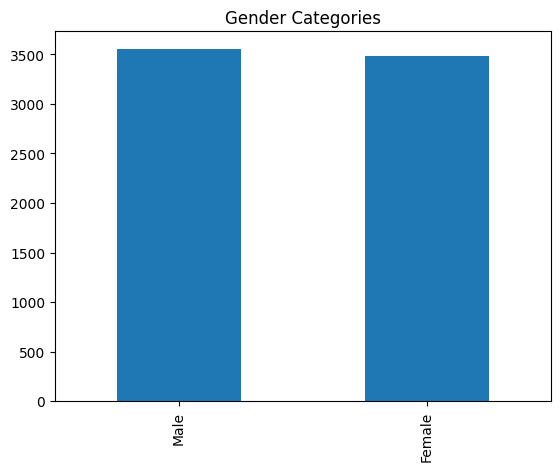

In [35]:
print("Unique values:", df['gender'].nunique())
print(df['gender'].value_counts())

df['gender'].value_counts().plot(kind='bar')
plt.title('Gender Categories')
plt.show()

## Column Analysis: SeniorCitizen

Unique values: 2
0    5901
1    1142
Name: SeniorCitizen, dtype: int64


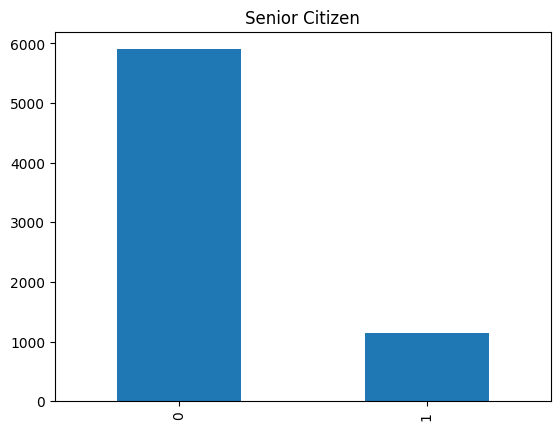

In [36]:
print("Unique values:", df['SeniorCitizen'].nunique())
print(df['SeniorCitizen'].value_counts())

df['SeniorCitizen'].value_counts().plot(kind='bar')
plt.title('Senior Citizen')
plt.show()
    

## Column Analysis: Partner

Unique values: 2
No     3641
Yes    3402
Name: Partner, dtype: int64


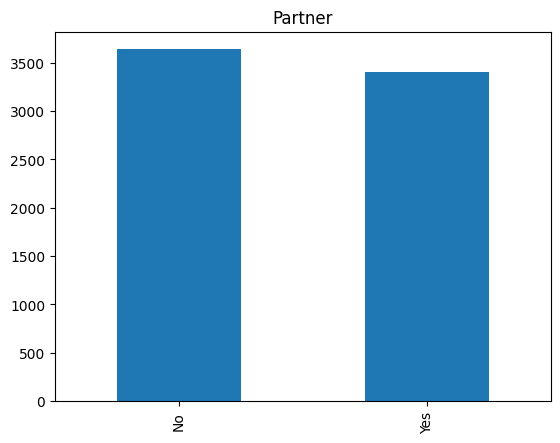

In [37]:
print("Unique values:", df['Partner'].nunique())
print(df['Partner'].value_counts())

df['Partner'].value_counts().head(10).plot(kind='bar')
plt.title('Partner')
plt.show()

## Column Analysis: Dependents

Unique values: 2
No     4933
Yes    2110
Name: Dependents, dtype: int64


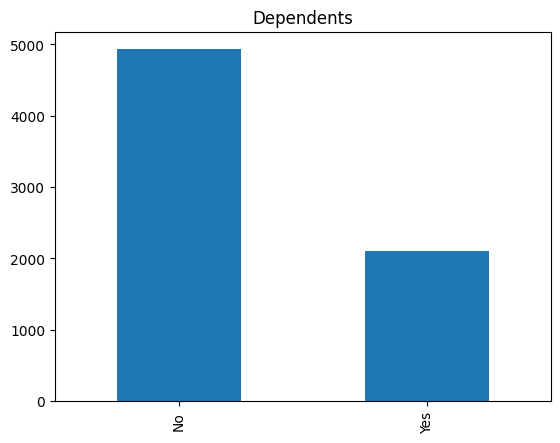

In [38]:
print("Unique values:", df['Dependents'].nunique())
print(df['Dependents'].value_counts())

df['Dependents'].value_counts().plot(kind='bar')
plt.title('Dependents')
plt.show()

## Column Analysis: tenure

Unique values: 73
1     613
72    362
2     238
3     200
4     176
     ... 
28     57
39     56
44     51
36     50
0      11
Name: tenure, Length: 73, dtype: int64


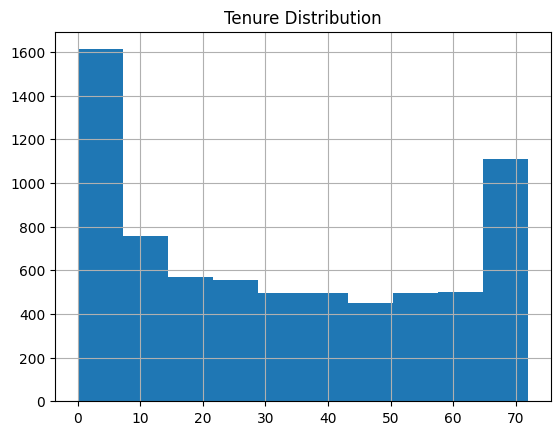

In [39]:
print("Unique values:", df['tenure'].nunique())
print(df['tenure'].value_counts())

df['tenure'].hist()
plt.title('Tenure Distribution')
plt.show()

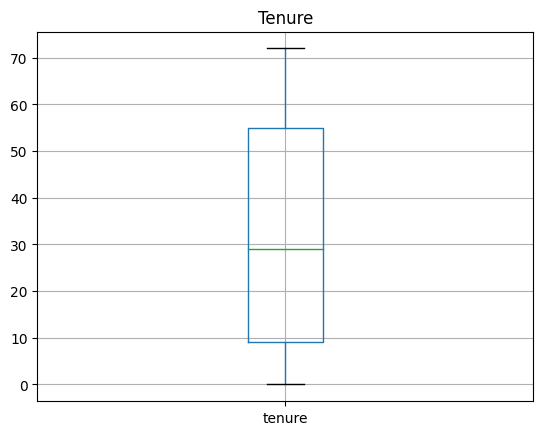

In [87]:
df.boxplot(column='tenure')
plt.title('Tenure')
plt.show()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


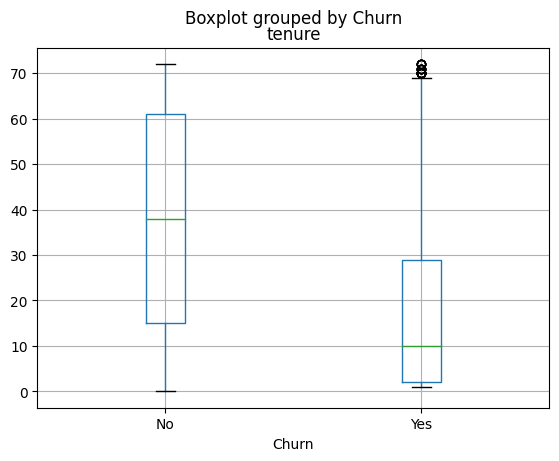

In [88]:
print(df.groupby('Churn')['tenure'].mean())

df.boxplot(column='tenure', by='Churn')
plt.show()

## Column Analysis: PhoneService

Unique values: 2
Yes    6361
No      682
Name: PhoneService, dtype: int64


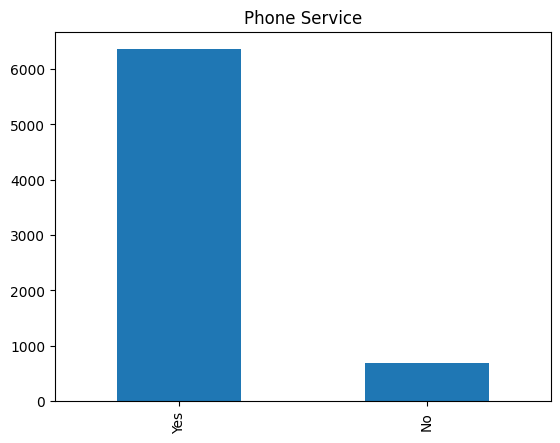

In [40]:
print("Unique values:", df['PhoneService'].nunique())
print(df['PhoneService'].value_counts())

df['PhoneService'].value_counts().plot(kind='bar')
plt.title('Phone Service')
plt.show()

## Column Analysis: MultipleLines

Unique values: 3
No                  3390
Yes                 2971
No phone service     682
Name: MultipleLines, dtype: int64


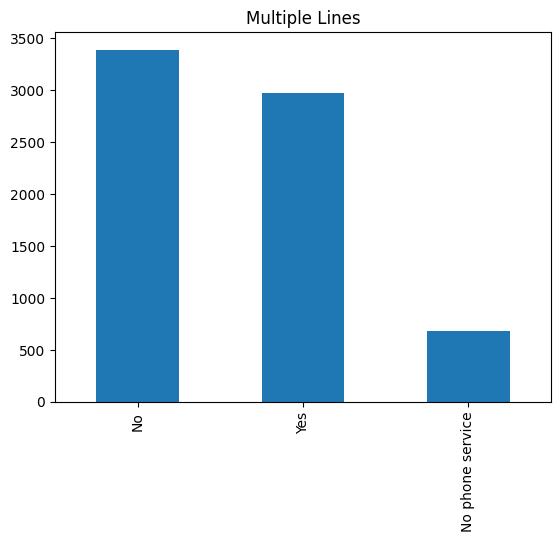

In [43]:
print("Unique values:", df['MultipleLines'].nunique())
print(df['MultipleLines'].value_counts())

df['MultipleLines'].value_counts().plot(kind='bar')
plt.title('Multiple Lines')
plt.show()

## Column Analysis: InternetService

Unique values: 3
Fiber optic    3096
DSL            2421
No             1526
Name: InternetService, dtype: int64


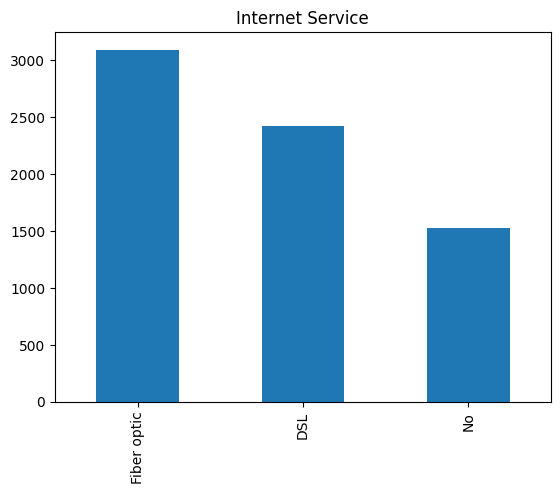

In [44]:
print("Unique values:", df['InternetService'].nunique())
print(df['InternetService'].value_counts())

df['InternetService'].value_counts().plot(kind='bar')
plt.title('Internet Service')
plt.show()

## Column Analysis: OnlineSecurity

Unique values: 3
No                     3498
Yes                    2019
No internet service    1526
Name: OnlineSecurity, dtype: int64


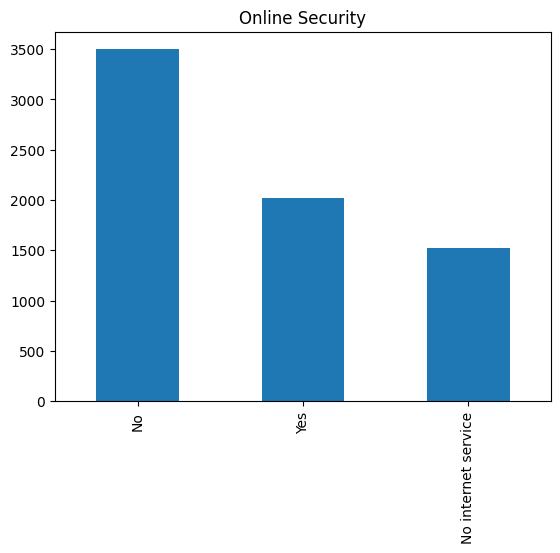

In [45]:
print("Unique values:", df['OnlineSecurity'].nunique())
print(df['OnlineSecurity'].value_counts())

df['OnlineSecurity'].value_counts().head(10).plot(kind='bar')
plt.title('Online Security')
plt.show()

## Column Analysis: OnlineBackup

Unique values: 3
No                     3088
Yes                    2429
No internet service    1526
Name: OnlineBackup, dtype: int64


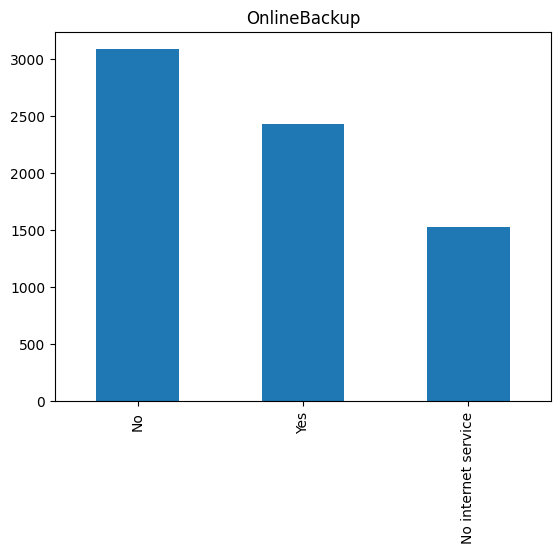

In [46]:
print("Unique values:", df['OnlineBackup'].nunique())
print(df['OnlineBackup'].value_counts())

df['OnlineBackup'].value_counts().head(10).plot(kind='bar')
plt.title('OnlineBackup')
plt.show()

## Column Analysis: DeviceProtection

Unique values: 3
No                     3095
Yes                    2422
No internet service    1526
Name: DeviceProtection, dtype: int64


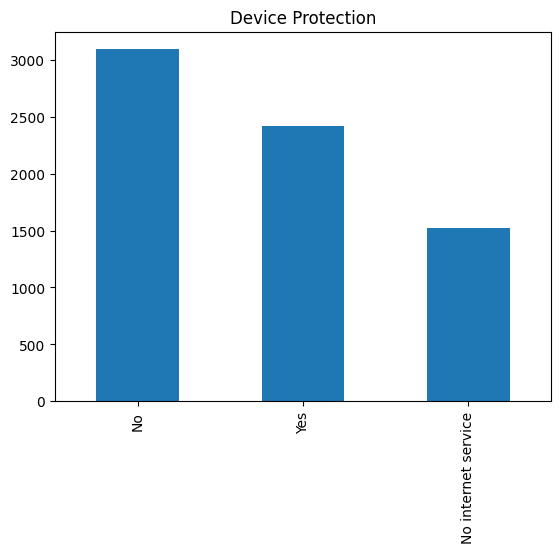

In [47]:
print("Unique values:", df['DeviceProtection'].nunique())
print(df['DeviceProtection'].value_counts())

df['DeviceProtection'].value_counts().head(10).plot(kind='bar')
plt.title('Device Protection')
plt.show()

## Column Analysis: TechSupport

Unique values: 3
No                     3473
Yes                    2044
No internet service    1526
Name: TechSupport, dtype: int64


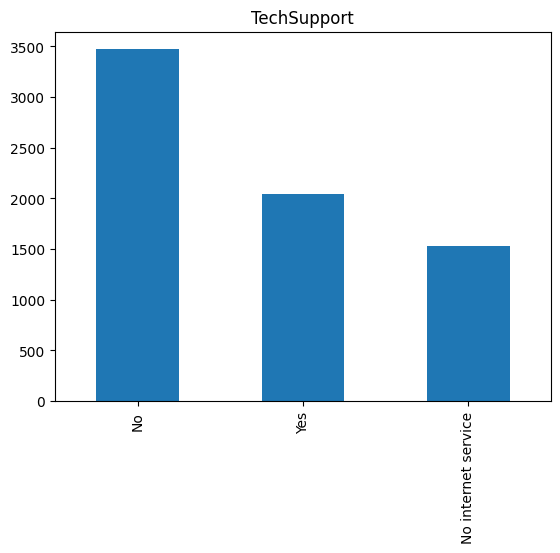

In [50]:
print("Unique values:", df['TechSupport'].nunique())
print(df['TechSupport'].value_counts())

df['TechSupport'].value_counts().plot(kind='bar')
plt.title('TechSupport')
plt.show()

## Column Analysis: StreamingTV

Unique values: 3
No                     2810
Yes                    2707
No internet service    1526
Name: StreamingTV, dtype: int64


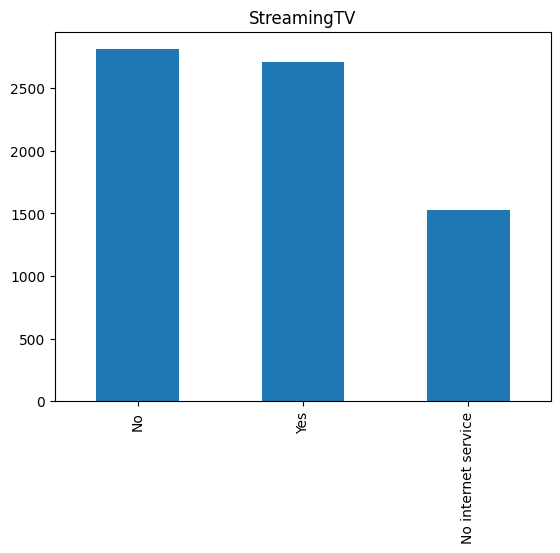

In [51]:
print("Unique values:", df['StreamingTV'].nunique())
print(df['StreamingTV'].value_counts())

df['StreamingTV'].value_counts().plot(kind='bar')
plt.title('StreamingTV')
plt.show()

## Column Analysis: StreamingMovies

Unique values: 3
No                     2785
Yes                    2732
No internet service    1526
Name: StreamingMovies, dtype: int64


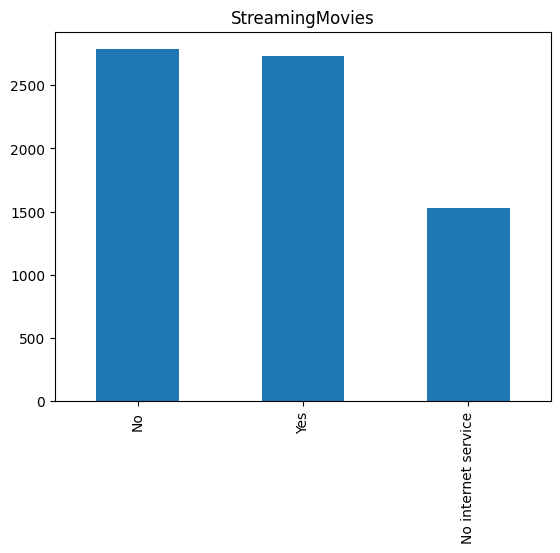

In [52]:
print("Unique values:", df['StreamingMovies'].nunique())
print(df['StreamingMovies'].value_counts())

df['StreamingMovies'].value_counts().plot(kind='bar')
plt.title('StreamingMovies')
plt.show()

## Column Analysis: Contract

Unique values: 3
Month-to-month    3875
Two year          1695
One year          1473
Name: Contract, dtype: int64


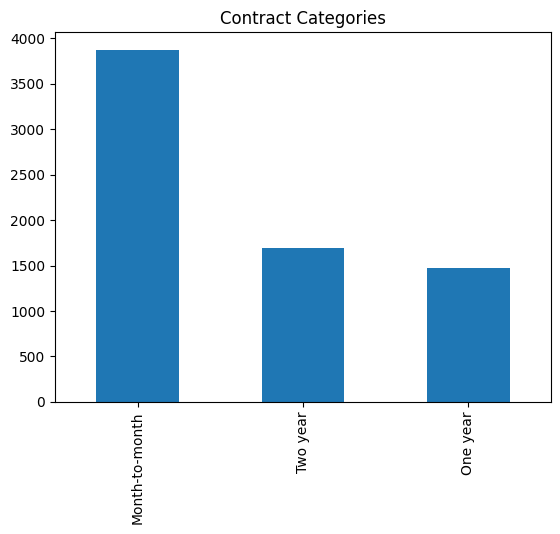

In [53]:
print("Unique values:", df['Contract'].nunique())
print(df['Contract'].value_counts())

df['Contract'].value_counts().plot(kind='bar')
plt.title('Contract Categories')
plt.show()

## Column Analysis: PaperlessBilling

Unique values: 2
Yes    4171
No     2872
Name: PaperlessBilling, dtype: int64


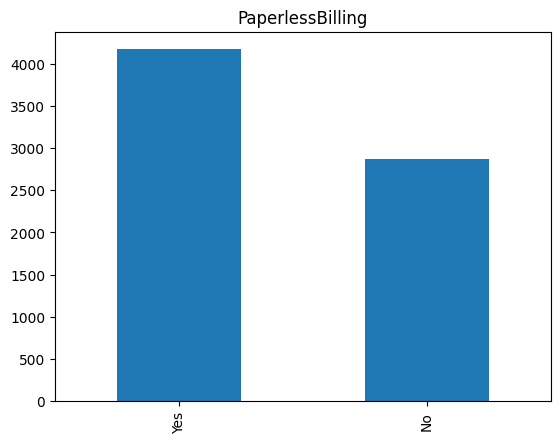

In [55]:
print("Unique values:", df['PaperlessBilling'].nunique())
print(df['PaperlessBilling'].value_counts())

df['PaperlessBilling'].value_counts().plot(kind='bar')
plt.title('PaperlessBilling')
plt.show()

## Column Analysis: PaymentMethod

Unique values: 4
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: PaymentMethod, dtype: int64


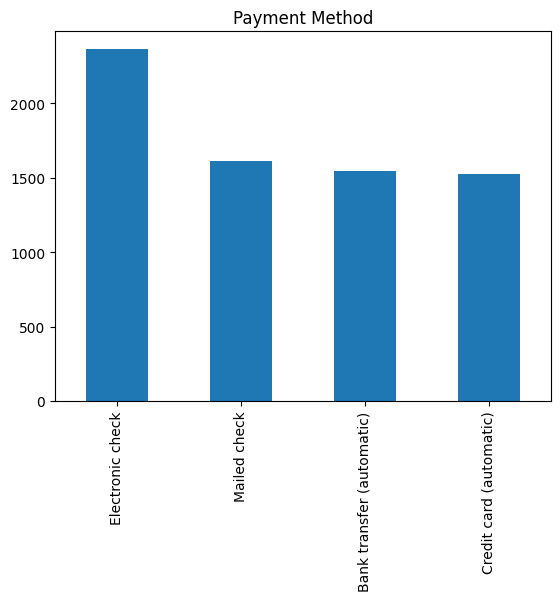

In [56]:
print("Unique values:", df['PaymentMethod'].nunique())
print(df['PaymentMethod'].value_counts())

df['PaymentMethod'].value_counts().plot(kind='bar')
plt.title('Payment Method')
plt.show()

## Column Analysis: MonthlyCharges

20.05     61
19.85     45
19.95     44
19.90     44
20.00     43
          ..
23.65      1
114.70     1
43.65      1
87.80      1
78.70      1
Name: MonthlyCharges, Length: 1585, dtype: int64


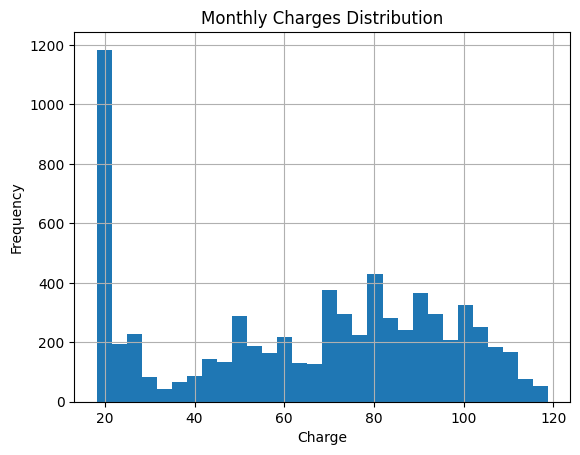

In [75]:
print(df['MonthlyCharges'].value_counts())

df['MonthlyCharges'].hist(bins=30)
plt.title('Monthly Charges Distribution')
plt.xlabel('Charge')
plt.ylabel('Frequency')
plt.show()


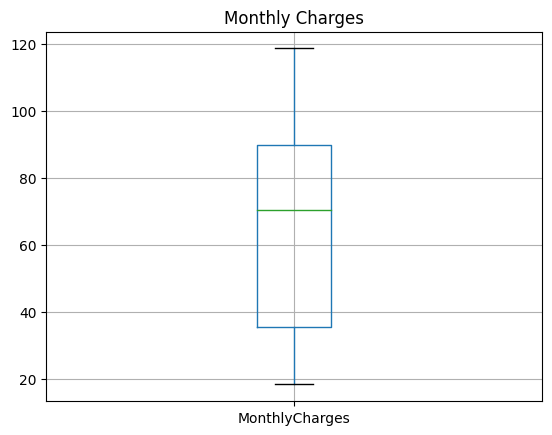

In [60]:
df.boxplot(column='MonthlyCharges')
plt.title('Monthly Charges')
plt.show()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


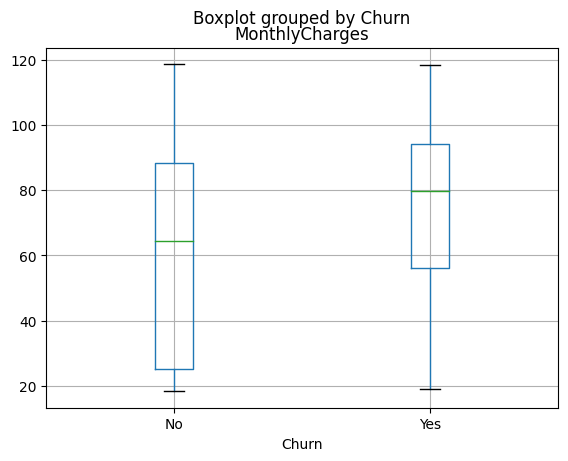

In [69]:
print(df.groupby('Churn')['MonthlyCharges'].mean())

df.boxplot(column='MonthlyCharges', by='Churn')
plt.show()

## Column Analysis: TotalCharges

In [80]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['MonthlyCharges'])

In [85]:
df['TotalCharges'].describe()

count    7043.000000
mean     2279.798992
std      2266.730170
min        18.800000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64

20.20      11
19.75       9
19.65       8
20.05       8
19.90       8
           ..
6849.40     1
692.35      1
130.15      1
3211.90     1
6844.50     1
Name: TotalCharges, Length: 6534, dtype: int64


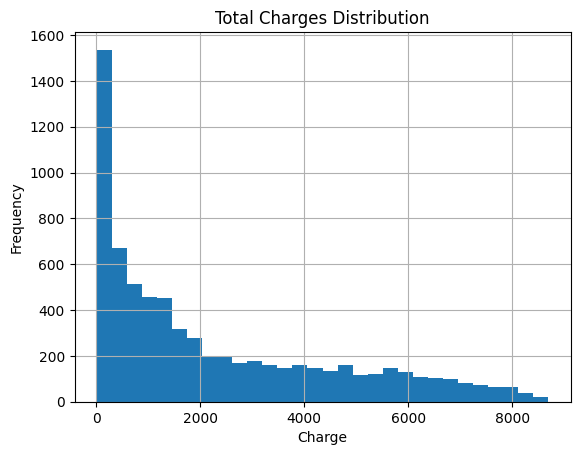

In [81]:
print(df['TotalCharges'].value_counts())

df['TotalCharges'].hist(bins=30)
plt.title('Total Charges Distribution')
plt.xlabel('Charge')
plt.ylabel('Frequency')
plt.show()

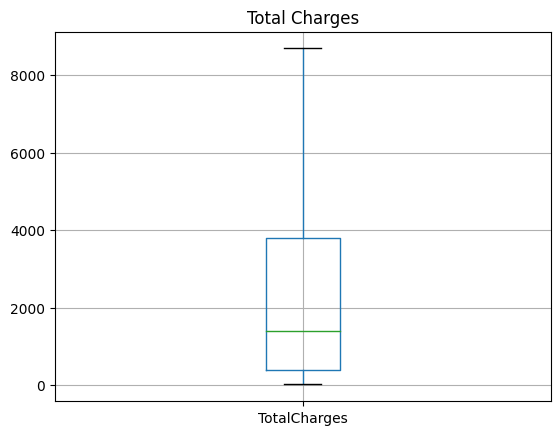

In [84]:
df.boxplot(column='TotalCharges')
plt.title('Total Charges')
plt.show()

Churn
No     2549.999497
Yes    1531.796094
Name: TotalCharges, dtype: float64


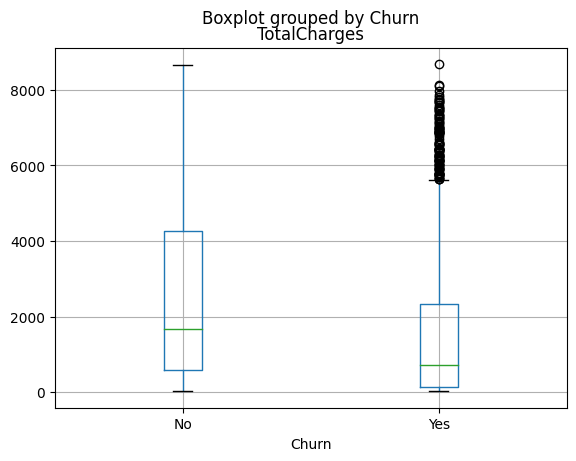

In [83]:
print(df.groupby('Churn')['TotalCharges'].mean())

df.boxplot(column='TotalCharges', by='Churn')
plt.show()

## Column Analysis: Churn

Unique values: 2
No     5174
Yes    1869
Name: Churn, dtype: int64


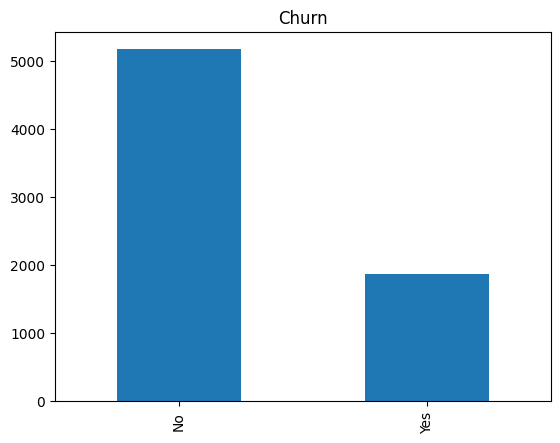

In [82]:
print("Unique values:", df['Churn'].nunique())
print(df['Churn'].value_counts())

df['Churn'].value_counts().plot(kind='bar')
plt.title('Churn')
plt.show()

## Correlation Analysis

In [ ]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [99]:
cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']

corr = df[cols].corr()['Churn'].sort_values(ascending=False)
print(corr)

Churn             1.000000
MonthlyCharges    0.193356
TotalCharges     -0.198347
tenure           -0.352229
Name: Churn, dtype: float64


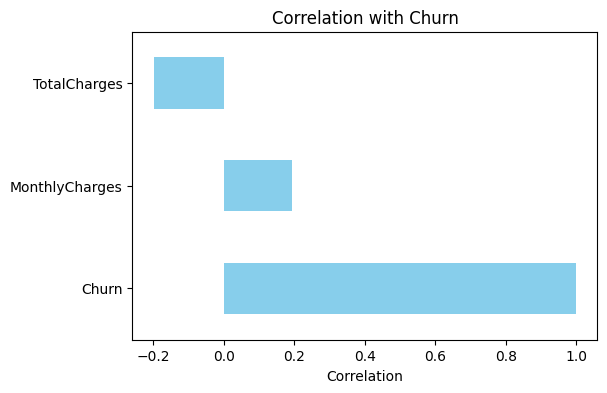

In [103]:
plt.figure(figsize=(6,4))
corr[:-1].plot(kind='barh', color='skyblue')
plt.title('Correlation with Churn')
plt.xlabel('Correlation')
plt.show()

In [ ]:
corr_matrix = df[cols].corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

In [104]:
binary_cols = ['Partner','Dependents','PaperlessBilling','OnlineSecurity','OnlineBackup',
               'DeviceProtection','TechSupport','StreamingTV','StreamingMovies']

for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})
    
df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})

multi_cols = ['InternetService','Contract','PaymentMethod','MultipleLines']
df = pd.get_dummies(df, columns=multi_cols, drop_first=True)

In [ ]:
demographics_cols = [
    'Gender', 
    'SeniorCitizen', 
    'Partner', 
    'Dependents',
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'Contract',
    'PaymentMethod',
    'PaperlessBilling'
]


final_cols = [c for c in df.columns if c in demographics_cols or 'InternetService_' in c
              or 'Contract_' in c or 'PaymentMethod_' in c or 'MultipleLines_' in c] + ['Churn']

In [ ]:
corr = df[final_cols].corr()['Churn'].sort_values(ascending=False)
print("Top correlations with Churn:")
print(corr)

plt.figure(figsize=(8,10))
sns.heatmap(df[final_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Demographic Feature Correlation with Churn')
plt.show()

In [ ]:
corr_churn = df[final_cols].corr()['Churn'].drop('Churn').sort_values(ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(x=corr_churn.values, y=corr_churn.index, palette='coolwarm')
plt.title('Correlation of Demographic Features with Churn')
plt.xlabel('Correlation with Churn')
plt.ylabel('Feature')
plt.show()